# MicroMate registration: TRE experiments and figures

Runs the GitLab CMA-ES solver (`cmaes_package`, unchanged) on simulated data, computes target registration error (TRE), and makes every figure for the weekly slides.

**How to use**
- Set the paths and flags in **Config**. With `RUN_EXPERIMENTS = False` the main sweeps load from `results.csv` (about a minute total); set it to `True` to rerun them (about 10 min).
- Colors, fonts and the figure-saving helper live in **Style**. Change them there and rerun to restyle every figure.
- Each figure has its own cell. Edit and rerun just that cell. Figures save to `OUT/` as PNG and also show inline.
- Keep `common.py`, `robust.py`, `detector.py`, `run_new.py`, `run_det.py`, `math_figs.py` in the same folder as this notebook (used by the newer sections).
- Every figure section lists its **assumptions** right above the code.

## Config

In [1]:
REPO = "micromate_robot_registration-main"   # path to the GitLab repo
OUT = "figs"                                   # where figures and CSVs go
RUN_EXPERIMENTS = False                        # True = rerun the 4 sweeps (~10 min)
N_TRIALS = 15                                  # trials per sweep setting
SUCCESS_MM = 2.0                               # a trial succeeds if RMS TRE over the grid < this
DPI = 130
RUN_NEW_EXPERIMENTS = False                    # True = rerun the cost / view / detector experiments (~25 min)

## Imports

In [2]:
import os, sys, time, warnings, logging
warnings.filterwarnings("ignore"); logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
%matplotlib inline

sys.path.insert(0, os.path.abspath(REPO)); sys.path.insert(0, os.path.abspath(".")); os.makedirs(OUT, exist_ok=True)
from cmaes_package.io import get_robot_fiducials
from cmaes_package.transform import make_T_from_rvec_tvec, make_random_displacement_pose
from cmaes_package.projection import project_point
from cmaes_package.synth_camera import make_intrinsics, make_orbit_projections
from cmaes_package.solver import (cmaes_centroid_aligned_initial_guess_from_gt_rotation,
                                  solve_pose_CMAES_closest_point, closest_point_rmse_objective)

## Style
Black background; yellow = main / success, gray = context, orange = failure.

In [3]:
BG, Y, G, L, R = "#000000", "#FFD60A", "#8A8A8A", "#EDEDED", "#FF6B35"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "axes.edgecolor": G,
    "axes.labelcolor": L, "xtick.color": L, "ytick.color": L, "text.color": L, "font.size": 15,
    "font.family": ["Arial", "Liberation Sans", "DejaVu Sans"], "legend.labelcolor": L,
    "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.savefig(os.path.join(OUT, name), dpi=DPI, bbox_inches="tight", pad_inches=0.15)
    plt.show()

def frame(ax):   # thin gray frame for image-like panels
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color("#333")

## Scenario
- **Fiducials:** the 5 CAD points, moved by the same small fixed transform as the repo's final notebook.
- **Cameras:** pinhole sources on a 600 mm circle around the origin (x–z plane), aimed at the origin. The C-arm values (detector 1,200 mm from source, 976 px at 0.4 mm → f = 3000 px) are **assumptions**; swap in the real ones here.
- **Observations:** project, add Gaussian pixel noise, optionally delete or add points, then shuffle.

In [4]:
def apply_T(T, pts): return (T[:3, :3] @ pts.T).T + T[:3, 3]

T_SMALL = make_T_from_rvec_tvec(np.array([[np.pi/30], [np.pi/18], [np.pi/60]]), np.array([[0.5], [1.0], [2.0]]))
XYZ = apply_T(T_SMALL, get_robot_fiducials())

SAD, SDD, PIX, NPX = 600.0, 1200.0, 0.4, 976          # assumed geometry
K = make_intrinsics(SDD / PIX, SDD / PIX, NPX / 2, NPX / 2)
REAL3 = (120, 180, 240)                                 # view spacing used in the real-data notebook

def views(angles): return make_orbit_projections(K=K, angles_deg=tuple(angles), radius_mm=SAD)[0]
P3 = views(REAL3)

def observe(P_list, T, rng, noise_px=0.0, drop=0, extra=0):
    out = []
    for P in P_list:
        uv = np.vstack([project_point(x, P, T) for x in XYZ])
        uv = uv + rng.normal(scale=noise_px, size=uv.shape)
        if drop:  uv = uv[rng.choice(len(uv), len(uv) - drop, replace=False)]
        if extra:
            lo, hi = uv.min(0) - 40, uv.max(0) + 40
            uv = np.vstack([uv, rng.uniform(lo, hi, size=(extra, 2))])
        out.append(uv[rng.permutation(len(uv))])
    return out

## TRE
Both the estimated and the true transform are applied to a set of target points; TRE is the distance between where each sends every point.
The default target set is the repo's grid: 10×10×10 points filling a ~300 mm cube centred on the origin.

In [5]:
_L = np.array([416, 424, 416]) * 0.718
GRID = np.stack(np.meshgrid(*[np.linspace(-l / 2, l / 2, 10) for l in _L], indexing="xy"), -1).reshape(-1, 3)

def tre_per_point(T_est, T_gt, pts): return np.linalg.norm(apply_T(T_est, pts) - apply_T(T_gt, pts), axis=1)
def rms(x): return float(np.sqrt(np.mean(np.square(x))))
def T_of(p): return make_T_from_rvec_tvec(np.asarray(p[:3]), np.asarray(p[3:]))

def rot_err_deg(T_est, T_gt):
    Rr = T_est[:3, :3] @ T_gt[:3, :3].T
    return float(np.degrees(np.arccos(np.clip((np.trace(Rr) - 1) / 2, -1, 1))))

## One trial
Stage 1 and Stage 2 are the repo's functions. Stage 1's rotation guess is the **true rotation plus uniform noise** of ±`init_rot_err_deg` per Rodrigues component (that is how the repo does it).
`start_at_truth=True` skips Stage 1 and starts Stage 2 at the true pose (used for diagnosis).

In [6]:
def trial(rng, P_list, init_rot_err_deg=10.0, noise_px=0.5, drop=0, extra=0, rot_deg=20.0, trans_mm=15.0,
          start_at_truth=False, full=False):
    T_gt, rv, tv = make_random_displacement_pose(1.0, rng, max_rot_deg=rot_deg, max_trans_mm=trans_mm)
    p_gt = np.r_[rv.ravel(), tv.ravel()]
    Yobs = observe(P_list, T_gt, rng, noise_px, drop, extra)
    t0 = time.perf_counter()
    p0 = p_gt if start_at_truth else cmaes_centroid_aligned_initial_guess_from_gt_rotation(
        rng=rng, p_gt=p_gt, P_list=P_list, uv_list=Yobs, xyz=XYZ, DISP_DEG=init_rot_err_deg, tvec_center=np.zeros(3))[0]
    p, reproj, es, hist = solve_pose_CMAES_closest_point(P_list=P_list, uv_list=Yobs, xyz_list=XYZ, p0=p0,
        rot_step_deg=15.0, trans_step_mm=5.0, sigma0=1.0, popsize=100, maxiter=500, verbose=False)
    T_est = T_of(p); c = XYZ.mean(0, keepdims=True)
    r = dict(rms_tre_vol=rms(tre_per_point(T_est, T_gt, GRID)), rms_tre_fid=rms(tre_per_point(T_est, T_gt, XYZ)),
             reproj_rmse_px=reproj, rot_err_deg=rot_err_deg(T_est, T_gt),
             trans_err_mm=float(tre_per_point(T_est, T_gt, c)[0]),        # error at the fiducial centroid
             runtime_s=time.perf_counter() - t0, evals=int(es.countevals))
    if full: r.update(T_est=T_est, T_gt=T_gt, p_gt=p_gt, p0=p0, p=p, Y=Yobs, hist=hist)
    return r

## Main sweeps
One factor at a time from the default (3 views 60° apart, 0.5 px noise, ±10° rotation guess, all 5 detected).
Every setting reuses seed 1234, so the first trial's pose is shared across settings.

In [7]:
BASE = dict(angles=REAL3, noise_px=0.5, init_rot_err_deg=10.0, drop=0, extra=0)
CONFIGS = []
def add(exp, label, **kw): CONFIGS.append((exp, label, {**BASE, **kw}))
add("E1 views", "1 view (0°)", angles=(0,))
for a in (15, 30, 60, 90): add("E1 views", f"2 views, {a}° apart", angles=(0, a))
add("E1 views", "2 views, opposed (0/180°)", angles=(0, 180))
add("E1 views", "3 views, 60° apart", angles=REAL3)
add("E1 views", "4 views, 0/90/180/270°", angles=(0, 90, 180, 270))
for n in (0.0, 0.5, 1.0, 2.0, 4.0): add("E2 noise", f"{n:g} px", noise_px=n)
add("E3 detections", "all 5 detected")
add("E3 detections", "1 missing per view", drop=1); add("E3 detections", "2 missing per view", drop=2)
add("E3 detections", "1 spurious per view", extra=1); add("E3 detections", "2 spurious per view", extra=2)
for dd in (0, 10, 20, 30, 45): add("E4 init", f"±{dd}° per axis", init_rot_err_deg=float(dd))

csv = os.path.join(OUT, "results.csv")
if RUN_EXPERIMENTS or not os.path.exists(csv):
    rows = []
    for exp, label, c in CONFIGS:
        rng = np.random.default_rng(1234); Pl = views(c["angles"]); t = time.time()
        for i in range(N_TRIALS):
            r = trial(rng, Pl, c["init_rot_err_deg"], c["noise_px"], c["drop"], c["extra"])
            rows.append({**r, "experiment": exp, "label": label, "trial": i})
        print(f"{exp:14s} {label:28s} {time.time() - t:5.1f}s")
    pd.DataFrame(rows).to_csv(csv, index=False)
df = pd.read_csv(csv)
def d_exp(exp): return df[df.experiment == exp]

df.groupby(["experiment", "label"], sort=False).rms_tre_vol.agg(
    success=lambda v: (v < SUCCESS_MM).mean() * 100, median="median", worst="max").round(2)

success  median     worst
experiment    label                                               
E1 views      1 view (0°)                  53.33    1.80  23872.78
              2 views, 15° apart          100.00    0.55      1.30
              2 views, 30° apart          100.00    0.53      1.28
              2 views, 60° apart          100.00    0.55      1.36
              2 views, 90° apart          100.00    0.53      1.27
              2 views, opposed (0/180°)   100.00    0.79      1.14
              3 views, 60° apart          100.00    0.46      0.86
              4 views, 0/90/180/270°      100.00    0.34      0.86
E2 noise      0 px                        100.00    0.00      0.00
              0.5 px                      100.00    0.46      0.86
              1 px                        100.00    0.92      1.73
              2 px                         53.33    1.83      3.47
              4 px                         20.00    3.68      6.98
E3 detections all 5 detected              100.00    0.46      0.86
              1 missing per view            0.00   29.10     93.80
              2 missing per view            0.00   78.78    177.15
              1 spurious per view         100.00    0.39      0.92
              2 spurious per view         100.00    0.37      0.72
E4 init       ±0° per axis                100.00    0.46      0.86
              ±10° per axis               100.00    0.46      0.86
              ±20° per axis               100.00    0.46      0.86
              ±30° per axis               100.00    0.46      0.86
              ±45° per axis               100.00    0.46      0.86

## Mathematical methods

**Pose.** $p=(\mathbf r,\mathbf t)\in\mathbb R^6$, rotation $R=\exp([\mathbf r]_\times)$ (Rodrigues vector, radians), translation $\mathbf t$ (mm), $T(p)=\begin{bmatrix}R&\mathbf t\\0&1\end{bmatrix}$.

**Projection.** For view $k$ with $P_k\in\mathbb R^{3\times4}$ and CAD fiducial $X_i$ ($i=1..N$, $N=5$):
$\tilde u_{ki}=P_k\,T(p)\,\tilde X_i$, $\;u_{ki}(p)=(\tilde u_1/\tilde u_3,\ \tilde u_2/\tilde u_3)$ in pixels.

**Simulated detections.** $\mathcal Y_k=\operatorname{shuffle}\big(\{u_{ki}(p^*)+\varepsilon_{ki}: i\in V_k\}\cup C_k\big)$, $\varepsilon\sim\mathcal N(0,\sigma^2I)$; $V_k$ = visible fiducials, $C_k$ = clutter points uniform within 40 px of the cluster's bounding box. $M_k=|\mathcal Y_k|$.

**Stage 1.** $\mathbf r_0=\mathbf r^*+\delta$, $\delta\sim U[-\Delta,\Delta]^3$ (uses ground truth); $\mathbf t_0=\arg\min_{\mathbf t}\sum_k\lVert \pi_k(R_0\bar X+\mathbf t)-\bar y_k\rVert^2$ with $\bar X$ the 3D centroid and $\bar y_k$ the mean detection (CMA-ES, pop 50, 10 mm/unit).

**Stage 2.** CMA-ES over $p=p_0+Sz$, $S=\operatorname{diag}(15^\circ,15^\circ,15^\circ,5,5,5\text{ mm})$, $\sigma_0=1$, $\lambda=100$, ≤500 generations, minimising one of:

- distances $d_{kij}(p)=\lVert u_{ki}(p)-y_{kj}\rVert$, nearest-detection error $e_{ki}=\min_j d_{kij}$
- **repo** (loops over all $N$ fiducials): $f_{\text{repo}}=\sqrt{\tfrac{1}{2NK}\sum_k\sum_{i=1}^N e_{ki}^2}$
- **detections → fiducials** (loops over what was detected): $f_{\text{rev}}=\sqrt{\tfrac{1}{2\sum_kM_k}\sum_k\sum_{j=1}^{M_k}\min_i d_{kij}^2}$
- **best $m$ per view** (minimum number of fiducials): $f_m=\sqrt{\tfrac{1}{2\sum_k m_k}\sum_k\sum_{l=1}^{m_k}e_{k(l)}^2}$, $m_k=\min(m,M_k)$, $e_{k(1)}\le e_{k(2)}\le\dots$; $m=5$ is the repo cost.

**Why the repo cost fails with a missing ball.** If fiducial $i$ has no detection in view $k$, $e_{ki}(p^*)$ equals the distance to the nearest *other* ball (90–135 px here). The squared loss then prefers poses that spread that error over all balls.

**Metrics.** $\mathrm{TRE}(x)=\lVert\hat Tx-T^*x\rVert$; $\mathrm{TRE}_{\text{RMS}}=\sqrt{\tfrac1{|G|}\sum_{x\in G}\mathrm{TRE}(x)^2}$ over the 1,000-point grid $G$; success if $<2$ mm. Rotation error $\theta=\arccos\frac{\operatorname{tr}(\hat RR^{*\top})-1}{2}$; translation error $\mathrm{TRE}(\bar X)$.
View-pair consistency (no ground truth): $s=\max_{a<b}\sqrt{\tfrac1{|G|}\sum_{x\in G}\lVert\hat T_ax-\hat T_bx\rVert^2}$ where $\hat T_a$ uses only view pair $a$.

**Detector image model.** $A(u)=A_{\text{body}}+A_{\text{bone}}+\sum_i\mu_g\,\ell_i(u)$ ($\ell_i$ = chord through glass ball $i$), counts $I\sim\text{Poisson}(I_0e^{-A})$, image $=-\ln(I/I_0)$.
**Detector.** background removal → LoG at $s=r/\sqrt2$ → local maxima → robust fit of $a\sqrt{\rho^2-\lVert u-c\rVert^2}$ + quadratic background → keep if $|\rho/r-1|<0.25$ and $a\rho\in[0.5,1.8]\,\mu_g\cdot10$ mm → output $c$.

In [8]:
# render the equations as slide images (figs/m1_model.png, m2_costs.png, m3_metrics.png)
%run math_figs.py {OUT}
%matplotlib inline

math figures written


## Shared plot helpers

In [9]:
def strip_plot(exp, labels, colors, fname):
    """Per-trial dots (n=15 is too few for box plots), median bar, 2 mm line, log y, success rate on top."""
    sub = d_exp(exp); groups = list(dict.fromkeys(sub.label))
    fig, ax = plt.subplots(figsize=(11, 4.8)); jit = np.random.default_rng(0)
    for i, g in enumerate(groups):
        v = np.clip(sub[sub.label == g].rms_tre_vol.values, 1e-3, None); ok = v < SUCCESS_MM
        ax.scatter(i + jit.uniform(-.17, .17, len(v)), v, s=34, color=np.where(ok, colors[i], R), alpha=.85, lw=0)
        ax.plot([i - .28, i + .28], [np.median(v)] * 2, color=L, lw=2.5)
        ax.text(i, .96, f"{ok.mean() * 100:.0f}%", ha="center", color=Y if ok.all() else R, fontsize=15,
                fontweight="bold", transform=ax.get_xaxis_transform())
        if v.max() > 1000:
            ax.annotate(f"{v.max():,.0f} mm", (i, v.max()), xytext=(14, 0), textcoords="offset points", color=R, fontsize=11, va="center")
    ax.set_yscale("log"); ax.set_ylim(0.08, max(10, sub.rms_tre_vol.max()) * 30)
    ax.axhline(SUCCESS_MM, color=R, ls="--", lw=1.3)
    ax.text(len(groups) - .5, SUCCESS_MM * 1.15, f"{SUCCESS_MM:g} mm", color=R, ha="right", fontsize=12)
    ax.set_xticks(range(len(groups)), labels, fontsize=13); ax.set_ylabel("RMS TRE per trial (mm)")
    ax.set_xlim(-.6, len(groups) - .4)
    ax.text(-.55, .9, "success rate", color=G, fontsize=11, va="top", transform=ax.get_xaxis_transform())
    save(fig, fname)

def box(ax, x, y, w, h, head, body, edge=Y):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.04", fc="#151515", ec=edge, lw=1.6))
    ax.text(x + .05, y + h - .08, head, color=Y, fontsize=15, fontweight="bold", va="top")
    ax.text(x + .05, y + h - .5, body, color=L, fontsize=12, va="top", linespacing=1.45)
def arrow(ax, x1, x2, y): ax.annotate("", (x2, y), (x1, y), arrowprops=dict(arrowstyle="-|>", color=Y, lw=2))

# Methods figures
## 01 · How the solver works

**Assumptions:** Rotation guess built from the true rotation; Stage 2 cost = repo's nearest-detection cost; CMA-ES: pop 100, 15° / 5 mm steps, ≤500 generations.

<Figure size 640x480 with 0 Axes>

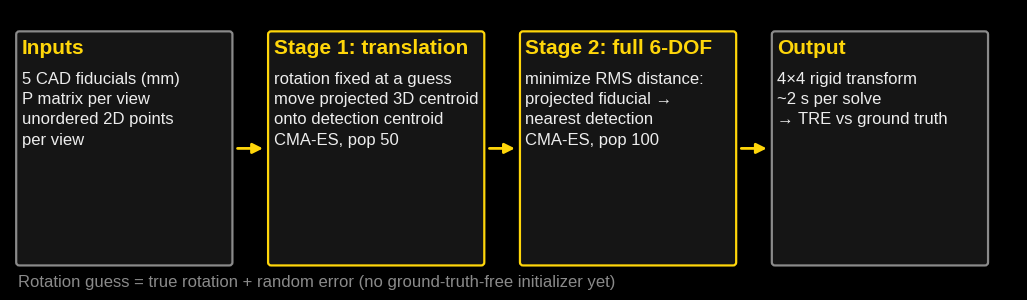

In [10]:
fig, ax = plt.subplots(figsize=(13, 3.6)); ax.set_xlim(0, 13); ax.set_ylim(0, 3.6); ax.axis("off")
steps = [("Inputs", "5 CAD fiducials (mm)\nP matrix per view\nunordered 2D points\nper view", G),
         ("Stage 1: translation", "rotation fixed at a guess\nmove projected 3D centroid\nonto detection centroid\nCMA-ES, pop 50", Y),
         ("Stage 2: full 6-DOF", "minimize RMS distance:\nprojected fiducial →\nnearest detection\nCMA-ES, pop 100", Y),
         ("Output", "4×4 rigid transform\n~2 s per solve\n→ TRE vs ground truth", G)]
for i, (h, b, e) in enumerate(steps):
    x = .1 + i * 3.25; box(ax, x, .3, 2.75, 3.0, h, b, e)
    if i < 3: arrow(ax, x + 2.8, x + 3.2, 1.8)
ax.text(.1, .0, "Rotation guess = true rotation + random error (no ground-truth-free initializer yet)", color=G, fontsize=12)
save(fig, "01_pipeline.png")

## 02 · How the test data is made

**Assumptions:** Everything in the top row is idealized; No image formation in the main sweeps.

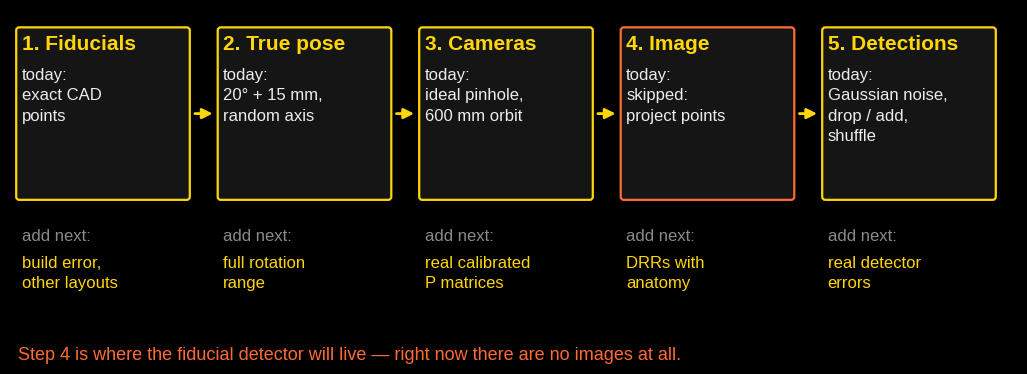

In [11]:
fig, ax = plt.subplots(figsize=(13, 4.6)); ax.set_xlim(0, 13); ax.set_ylim(0, 4.6); ax.axis("off")
gen = [("1. Fiducials", "exact CAD\npoints", "build error,\nother layouts"),
       ("2. True pose", "20° + 15 mm,\nrandom axis", "full rotation\nrange"),
       ("3. Cameras", "ideal pinhole,\n600 mm orbit", "real calibrated\nP matrices"),
       ("4. Image", "skipped:\nproject points", "DRRs with\nanatomy"),
       ("5. Detections", "Gaussian noise,\ndrop / add,\nshuffle", "real detector\nerrors")]
for i, (h, now, nxt) in enumerate(gen):
    x = .1 + i * 2.6
    box(ax, x, 2.15, 2.2, 2.2, h, "today:\n" + now, R if i == 3 else Y)
    ax.text(x + .05, 1.75, "add next:", color=G, fontsize=12, va="top")
    ax.text(x + .05, 1.4, nxt, color=Y, fontsize=12, va="top", linespacing=1.4)
    if i < 4: arrow(ax, x + 2.25, x + 2.55, 3.25)
ax.text(.1, .05, "Step 4 is where the fiducial detector will live — right now there are no images at all.", color=R, fontsize=13)
save(fig, "02_data_generation.png")

## 03 · Setup: geometry and what the solver receives

**Assumptions:** Assumed C-arm geometry (600 / 1,200 mm, 0.4 mm px); Views at 120°, 180°, 240° in one plane; Clutter: uniform within 40 px of the cluster.

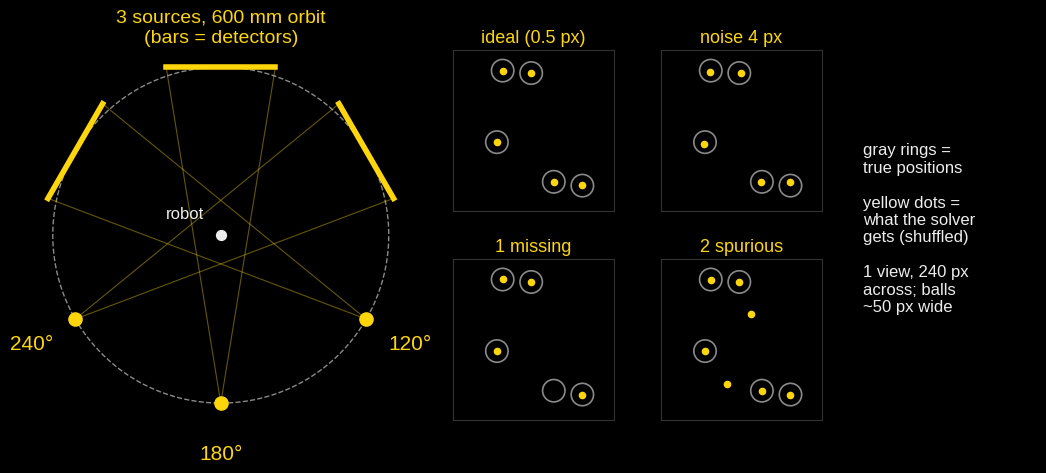

In [12]:
fig = plt.figure(figsize=(13, 4.8)); gs = fig.add_gridspec(2, 4, width_ratios=[2.2, 1, 1, 1], wspace=.15, hspace=.3)
ax = fig.add_subplot(gs[:, 0]); th = np.linspace(0, 2 * np.pi, 300)
ax.plot(SAD * np.sin(th), SAD * np.cos(th), color=G, lw=1, ls="--")
for a in REAL3:
    t = np.radians(a); c = SAD * np.array([np.sin(t), np.cos(t)]); dt = -c; perp = np.array([-c[1], c[0]]) / SAD * 195
    for sg in (1, -1): ax.plot([c[0], dt[0] + sg * perp[0]], [c[1], dt[1] + sg * perp[1]], color=Y, lw=.8, alpha=.4)
    ax.plot([dt[0] - perp[0], dt[0] + perp[0]], [dt[1] - perp[1], dt[1] + perp[1]], color=Y, lw=4)
    ax.scatter(*c, color=Y, s=90, zorder=3); ax.text(*(c * 1.3), f"{a}°", color=Y, ha="center", va="center")
ax.scatter(0, 0, color=L, s=50); ax.text(-60, 60, "robot", color=L, ha="right", fontsize=12)
ax.set_aspect("equal"); ax.axis("off"); ax.set_title("3 sources, 600 mm orbit\n(bars = detectors)", color=Y, fontsize=14)
rng0 = np.random.default_rng(3); T0, _, _ = make_random_displacement_pose(1.0, rng0, max_rot_deg=20, max_trans_mm=15)
clean = observe(P3, T0, rng0)[1]; c0 = clean.mean(0)
for k, (t, kw, sd) in enumerate([("ideal (0.5 px)", dict(noise_px=.5), 1), ("noise 4 px", dict(noise_px=4), 1),
                                 ("1 missing", dict(noise_px=.5, drop=1), 2), ("2 spurious", dict(noise_px=.5, extra=2), 4)]):
    a2 = fig.add_subplot(gs[k // 2, 1 + k % 2]); Yv = observe(P3, T0, np.random.default_rng(sd), **kw)[1]
    a2.scatter(*(clean - c0).T, s=260, facecolors="none", edgecolors=G, lw=1.2)
    a2.scatter(*(Yv - c0).T, color=Y, s=20, zorder=3)
    a2.set_title(t, color=Y, fontsize=13); a2.set_aspect("equal"); a2.set_xlim(-120, 120); a2.set_ylim(-120, 120); frame(a2)
a3 = fig.add_subplot(gs[:, 3]); a3.axis("off")
a3.text(0, .75, "gray rings =\ntrue positions\n\nyellow dots =\nwhat the solver\ngets (shuffled)\n\n1 view, 240 px\nacross; balls\n~50 px wide",
        color=L, fontsize=12, va="top", transform=a3.transAxes)
save(fig, "03_setup.png")

# Results
## 04 · Views

**Assumptions:** 0.5 px noise, ±10° rotation guess; All 5 fiducials detected; Repo cost; 15 trials per bar, success = RMS TRE < 2 mm over 300 mm grid.

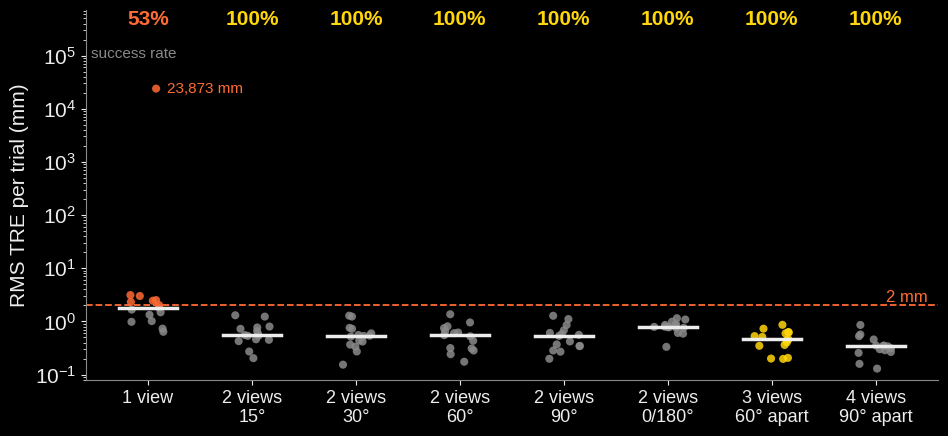

In [13]:
strip_plot("E1 views", ["1 view", "2 views\n15°", "2 views\n30°", "2 views\n60°", "2 views\n90°", "2 views\n0/180°",
                        "3 views\n60° apart", "4 views\n90° apart"], [G] * 6 + [Y, G], "04_views.png")

## 05 · Detection noise
Numeric x-axis, so a line of medians with every trial shown; the fitted slope is the mm-per-pixel sensitivity.

**Assumptions:** 3 views 60° apart, ±10° rotation guess; All 5 detected; Repo cost; Gaussian noise σ per coordinate (px); 15 trials per noise level.

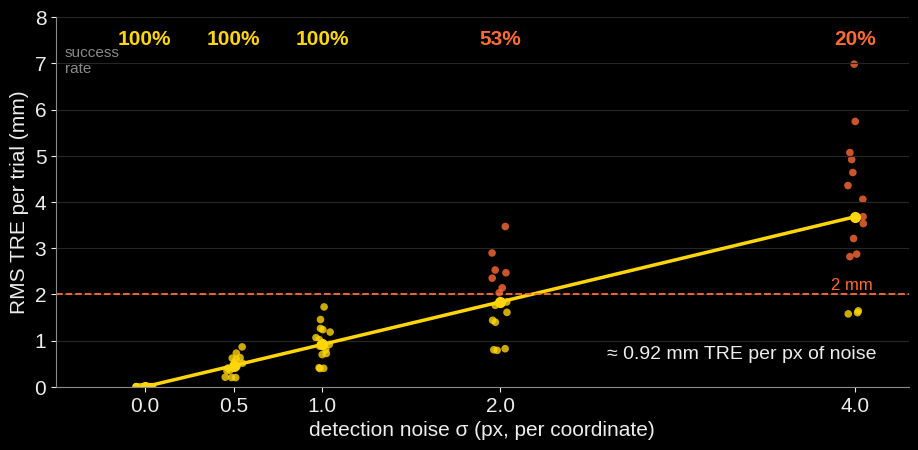

In [14]:
sub = d_exp("E2 noise"); nx = sub.label.str.replace(" px", "").astype(float)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.scatter(nx + np.random.default_rng(0).uniform(-.05, .05, len(nx)), sub.rms_tre_vol,
           color=np.where(sub.rms_tre_vol < SUCCESS_MM, Y, R), s=30, alpha=.8, lw=0)
med = sub.groupby(nx).rms_tre_vol.median(); succ = sub.groupby(nx).rms_tre_vol.apply(lambda v: (v < SUCCESS_MM).mean() * 100)
ax.plot(med.index, med.values, color=Y, lw=2.5, marker="o", ms=7)
slope = np.polyfit(med.index, med.values, 1)[0]
for xv, s_ in succ.items(): ax.text(xv, 7.4, f"{s_:.0f}%", ha="center", color=Y if s_ == 100 else R, fontweight="bold")
ax.text(-.45, 6.8, "success\nrate", color=G, fontsize=11)
ax.axhline(SUCCESS_MM, color=R, ls="--", lw=1.3); ax.text(4.1, SUCCESS_MM + .1, f"{SUCCESS_MM:g} mm", color=R, ha="right", fontsize=12)
ax.text(2.6, .6, f"≈ {slope:.2f} mm TRE per px of noise", color=L, fontsize=14)
ax.set_xticks(med.index); ax.set_xlabel("detection noise σ (px, per coordinate)"); ax.set_ylabel("RMS TRE per trial (mm)")
ax.set_ylim(0, 8); ax.set_xlim(-.5, 4.3); ax.grid(axis="y", color="#262626")
save(fig, "05_noise.png")

## 06 · Missing and spurious detections

**Assumptions:** 3 views, 0.5 px noise, ±10° guess; Repo cost (loops over all 5 fiducials); Missing: random ball(s) deleted, independently per view; Spurious: uniform within 40 px of the cluster.

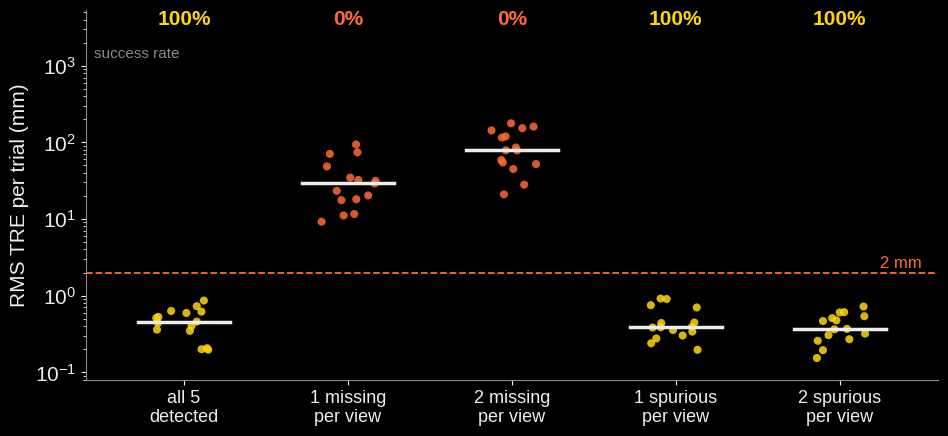

In [15]:
strip_plot("E3 detections", ["all 5\ndetected", "1 missing\nper view", "2 missing\nper view", "1 spurious\nper view",
                             "2 spurious\nper view"], [Y] * 5, "06_detections.png")

## 07 · A missing-detection failure, started at the true pose

**Assumptions:** Stage 2 started AT the true pose; 1 random ball missing per view, 0.5 px noise; Repo cost; One example trial.

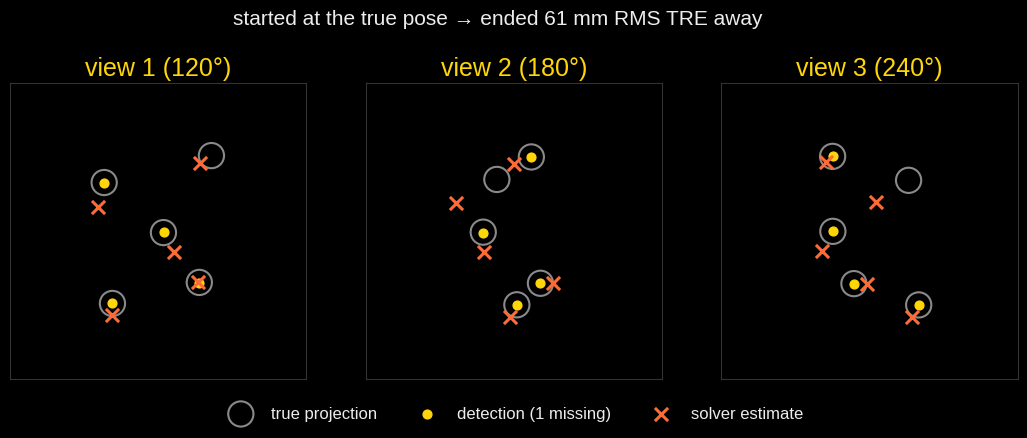

In [16]:
ex = trial(np.random.default_rng(7), P3, noise_px=.5, drop=1, start_at_truth=True, full=True)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.4))
for k, a2 in enumerate(axs):
    tr = np.vstack([project_point(x, P3[k], ex["T_gt"]) for x in XYZ]); es_ = np.vstack([project_point(x, P3[k], ex["T_est"]) for x in XYZ])
    c = tr.mean(0)
    a2.scatter(*(tr - c).T, s=330, facecolors="none", edgecolors=G, lw=1.5, label="true projection")
    a2.scatter(*(ex["Y"][k] - c).T, color=Y, s=40, zorder=3, label="detection (1 missing)")
    a2.scatter(*(es_ - c).T, marker="x", color=R, s=90, lw=2.2, zorder=4, label="solver estimate")
    a2.set_title(f"view {k + 1} ({REAL3[k]}°)", color=Y); a2.set_aspect("equal"); a2.set_xlim(-220, 220); a2.set_ylim(-220, 220); frame(a2)
axs[1].legend(loc="upper center", bbox_to_anchor=(.5, -.04), ncol=3, frameon=False, fontsize=12)
fig.suptitle(f"started at the true pose → ended {ex['rms_tre_vol']:.0f} mm RMS TRE away", color=L, fontsize=15, y=1.0)
save(fig, "07_missing_example.png")

## 08 · NEW · Why it fails: the cost along the line from the true pose to the solver's answer
Same case as figure 07. Poses are interpolated in parameter space: 0 = true pose, 1 = where the solver ended up.
With all 5 detections the cost is lowest at the truth; with one missing per view the cost is lowest at the **wrong** pose, so no optimizer or initializer can fix it. The objective itself has to change.

**Assumptions:** Same trial as the previous slide; Poses interpolated linearly in the 6 pose parameters; Cost = RMS per coordinate (px).

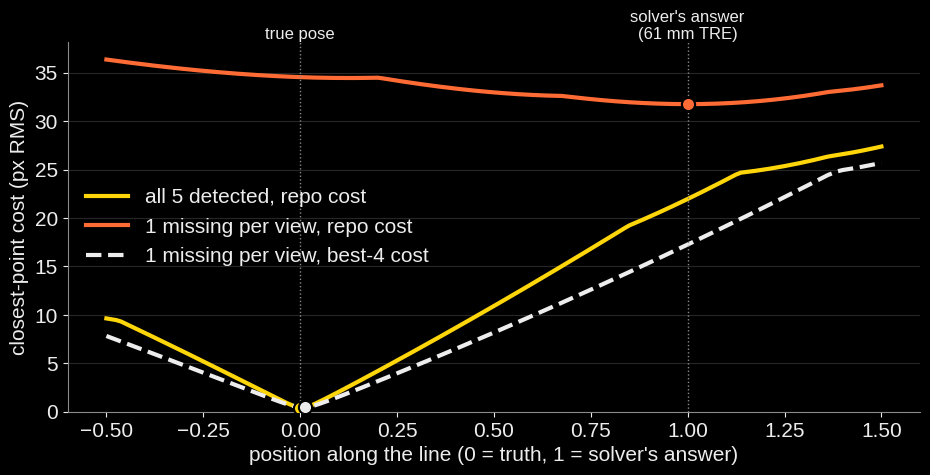

In [17]:
# same pose and same noise, but nothing deleted (observe draws noise first, then deletes)
rng_full = np.random.default_rng(7); make_random_displacement_pose(1.0, rng_full, max_rot_deg=20, max_trans_mm=15)
Y_full = observe(P3, ex["T_gt"], rng_full, noise_px=.5)
alphas = np.linspace(-.5, 1.5, 161); dp = ex["p"] - ex["p_gt"]
cost_full = [closest_point_rmse_objective(ex["p_gt"] + a * dp, P3, Y_full, XYZ) for a in alphas]
cost_miss = [closest_point_rmse_objective(ex["p_gt"] + a * dp, P3, ex["Y"], XYZ) for a in alphas]
from robust import make_cost_trimmed
best4 = make_cost_trimmed(4)
cost_fix = [best4(ex["p_gt"] + a * dp, P3, ex["Y"], XYZ) for a in alphas]
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(alphas, cost_full, color=Y, lw=3, label="all 5 detected, repo cost")
ax.plot(alphas, cost_miss, color=R, lw=3, label="1 missing per view, repo cost")
ax.plot(alphas, cost_fix, color=L, lw=3, ls="--", label="1 missing per view, best-4 cost")
for cst, col in ((cost_full, Y), (cost_miss, R), (cost_fix, L)):
    i = int(np.argmin(cst)); ax.scatter(alphas[i], cst[i], color=col, s=90, zorder=5, edgecolor=BG, lw=1.5)
for xv, t in ((0, "true pose"), (1, f"solver's answer\n({ex['rms_tre_vol']:.0f} mm TRE)")):
    ax.axvline(xv, color=G, lw=1, ls=":"); ax.text(xv, 1.0, t, color=L, ha="center", va="bottom", fontsize=12, transform=ax.get_xaxis_transform())
ax.set_xlabel("position along the line (0 = truth, 1 = solver's answer)"); ax.set_ylabel("closest-point cost (px RMS)")
ax.set_ylim(0, None); ax.legend(frameon=False, loc="center left"); ax.grid(axis="y", color="#262626")
save(fig, "08_cost_landscape.png")

## 09 · NEW · Convergence: what CMA-ES is doing iteration by iteration
5 trials each, clean vs one missing per view, from the usual Stage 1 start. The left panel is what the solver sees (cost); the right is what we care about (TRE).
With a missing detection the cost still goes down smoothly, so the solver "thinks" it is converging, while TRE stalls tens of mm off.

**Assumptions:** Repo cost; 5 trials per condition, normal Stage 1 start; TRE recomputed from the best pose at every iteration.

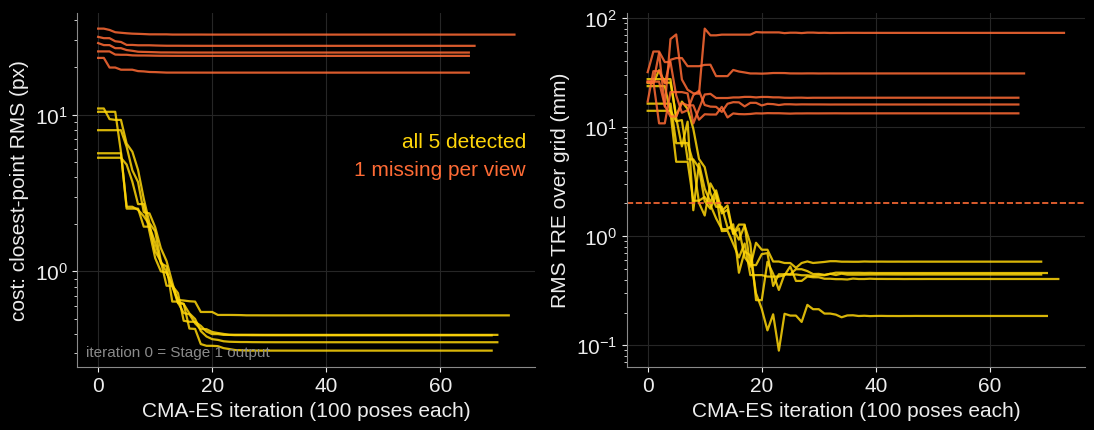

In [18]:
conv = []
for cond, kw, col in (("all 5 detected", dict(), Y), ("1 missing per view", dict(drop=1), R)):
    rng = np.random.default_rng(21)
    for i in range(5):
        r = trial(rng, P3, noise_px=.5, full=True, **kw)
        it = [0] + [h["iter"] for h in r["hist"]]
        cost = [closest_point_rmse_objective(r["p0"], P3, r["Y"], XYZ)] + [h["global_best_rmse"] for h in r["hist"]]
        tre = [rms(tre_per_point(T_of(r["p0"]), r["T_gt"], GRID))] + [rms(tre_per_point(T_of(h["best_p"]), r["T_gt"], GRID)) for h in r["hist"]]
        conv.append((cond, col, it, cost, tre))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for cond, col, it, cost, tre in conv:
    axs[0].plot(it, cost, color=col, lw=1.6, alpha=.85); axs[1].plot(it, tre, color=col, lw=1.6, alpha=.85)
for a2, yl in zip(axs, ("cost: closest-point RMS (px)", "RMS TRE over grid (mm)")):
    a2.set_yscale("log"); a2.set_xlabel("CMA-ES iteration (100 poses each)"); a2.set_ylabel(yl); a2.grid(color="#262626")
axs[1].axhline(SUCCESS_MM, color=R, ls="--", lw=1.2)
axs[0].text(.98, .62, "all 5 detected", color=Y, ha="right", transform=axs[0].transAxes)
axs[0].text(.98, .54, "1 missing per view", color=R, ha="right", transform=axs[0].transAxes)
axs[0].text(.02, .03, "iteration 0 = Stage 1 output", color=G, fontsize=11, transform=axs[0].transAxes)
save(fig, "09_convergence.png")

## 10 · NEW · Can we tell a failed solve without ground truth?
On real data TRE is unknown, but the final reprojection error (the solver's own cost) is not. Every trial from every sweep is plotted.
Missing-detection failures stand out with large residuals, so they can be flagged. Noise and single-view failures have normal-looking residuals and **cannot** be flagged this way.

**Assumptions:** Repo cost; All trials from the 4 main sweeps; Noise-free trials omitted (0 error).

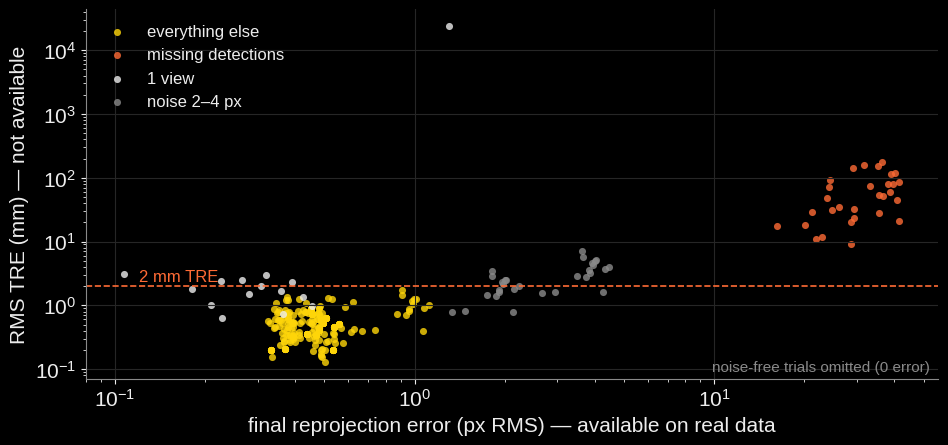

In [19]:
dfr = df[df.reproj_rmse_px > 1e-6]          # noise-free trials have exactly 0 error: can't show on log axes
cat = np.select([dfr.label.str.contains("missing"), dfr.label.str.startswith("1 view"), dfr.label.isin(["2 px", "4 px"])],
                ["missing detections", "1 view", "noise 2–4 px"], "everything else")
cols = {"everything else": Y, "missing detections": R, "1 view": L, "noise 2–4 px": G}
fig, ax = plt.subplots(figsize=(11, 4.8))
for k, col in cols.items():
    m = cat == k
    ax.scatter(dfr.reproj_rmse_px[m], dfr.rms_tre_vol[m], s=26, color=col, alpha=.8, lw=0, label=k)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axhline(SUCCESS_MM, color=R, ls="--", lw=1.2); ax.text(.12, SUCCESS_MM * 1.2, f"{SUCCESS_MM:g} mm TRE", color=R, fontsize=12)
ax.set_xlabel("final reprojection error (px RMS) — available on real data"); ax.set_ylabel("RMS TRE (mm) — not available")
ax.legend(frameon=False, fontsize=12, loc="upper left"); ax.grid(color="#262626")
ax.text(.99, .02, "noise-free trials omitted (0 error)", color=G, fontsize=11, ha="right", transform=ax.transAxes)
save(fig, "10_reproj_vs_tre.png")

## 11 · NEW · Which part of the pose goes wrong?
Small extra run (12 trials per condition, ~2 min, cached to `pose_errors.csv`). Rotation error is the angle of R_est·R_gtᵀ; translation error is measured at the fiducial centroid.

**Assumptions:** Repo cost, all 5 detected; 12 trials per condition; Translation error measured at the fiducial centroid.

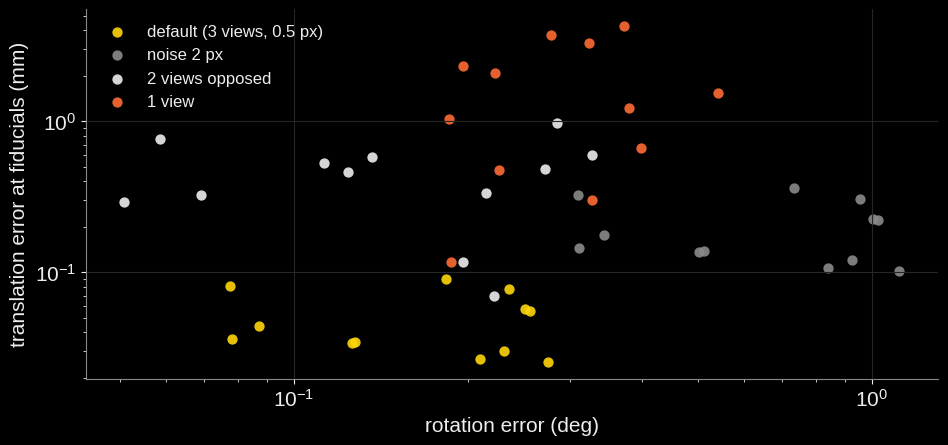

,rot_err_deg,trans_err_mm,rms_tre_vol
condition,,,
"default (3 views, 0.5 px)",0.197,0.040,0.481
noise 2 px,0.787,0.160,1.924
2 views opposed,0.166,0.472,0.604
1 view,0.301,1.383,1.763


In [20]:
pe_csv = os.path.join(OUT, "pose_errors.csv")
PE = [("default (3 views, 0.5 px)", dict(), Y), ("noise 2 px", dict(noise_px=2.0), G),
      ("2 views opposed", dict(angles=(0, 180)), L), ("1 view", dict(angles=(0,)), R)]
if RUN_EXPERIMENTS or not os.path.exists(pe_csv):
    rows = []
    for name, kw, _ in PE:
        rng = np.random.default_rng(99); Pl = views(kw.get("angles", REAL3))
        for i in range(12):
            r = trial(rng, Pl, noise_px=kw.get("noise_px", .5)); rows.append({**r, "condition": name})
    pd.DataFrame(rows).to_csv(pe_csv, index=False)
pe = pd.read_csv(pe_csv)
fig, ax = plt.subplots(figsize=(11, 4.8))
for name, _, col in PE:
    m = pe.condition == name
    ax.scatter(pe.rot_err_deg[m], pe.trans_err_mm[m], s=55, color=col, alpha=.9, lw=0, label=name)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("rotation error (deg)"); ax.set_ylabel("translation error at fiducials (mm)")
ax.legend(frameon=False, fontsize=12, loc="upper left"); ax.grid(color="#262626")
save(fig, "11_rot_vs_trans.png")
pe.groupby("condition", sort=False)[["rot_err_deg", "trans_err_mm", "rms_tre_vol"]].median().round(3)

## 12 · TRE depends on where you measure it
Per-point TRE vs distance from the fiducial centroid: a small rotation error times the lever arm.

**Assumptions:** Repo cost, 3 views, 0.5 px, all detected; 8 trials; Per-point TRE over the 1,000-point grid.

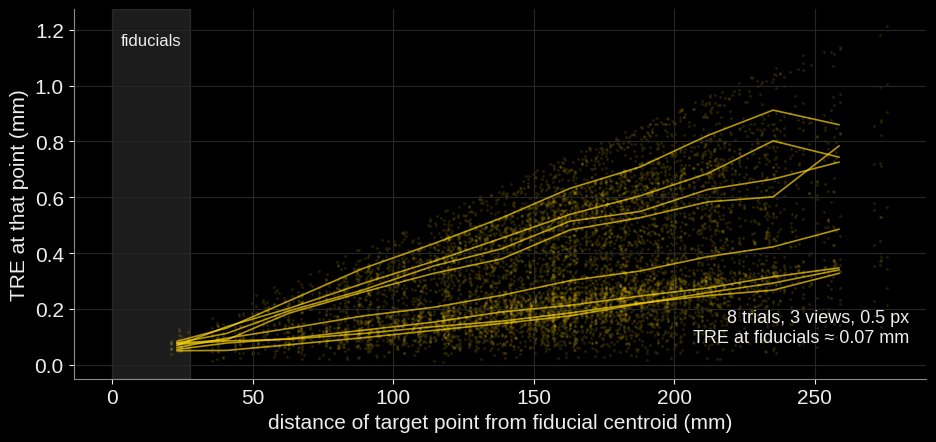

In [21]:
rng = np.random.default_rng(11); cen = XYZ.mean(0); dist = np.linalg.norm(GRID - cen, axis=1)
fig, ax = plt.subplots(figsize=(11, 4.8)); fid_tre = []
bins = np.linspace(0, dist.max(), 12); idx = np.digitize(dist, bins)
for i in range(8):
    r = trial(rng, P3, noise_px=.5, full=True); tp = tre_per_point(r["T_est"], r["T_gt"], GRID); fid_tre.append(r["rms_tre_fid"])
    ax.scatter(dist, tp, s=4, color=Y, alpha=.15, lw=0)
    ok = [b for b in range(1, 12) if (idx == b).any()]
    ax.plot([dist[idx == b].mean() for b in ok], [np.median(tp[idx == b]) for b in ok], color=Y, lw=1.2, alpha=.7)
ax.axvspan(0, np.linalg.norm(XYZ - cen, axis=1).max(), color=L, alpha=.12)
ax.text(3, ax.get_ylim()[1] * .9, "fiducials", color=L, fontsize=12)
ax.set_xlabel("distance of target point from fiducial centroid (mm)"); ax.set_ylabel("TRE at that point (mm)")
ax.text(.98, .1, f"8 trials, 3 views, 0.5 px\nTRE at fiducials ≈ {np.median(fid_tre):.2f} mm", transform=ax.transAxes, ha="right", fontsize=13)
ax.grid(color="#262626")
save(fig, "12_tre_vs_distance.png")

## 13 · Rotation guess

**Assumptions:** Repo cost, 3 views, 0.5 px, all detected; Guess = true rotation + uniform error per Rodrigues component; 15 trials per setting.

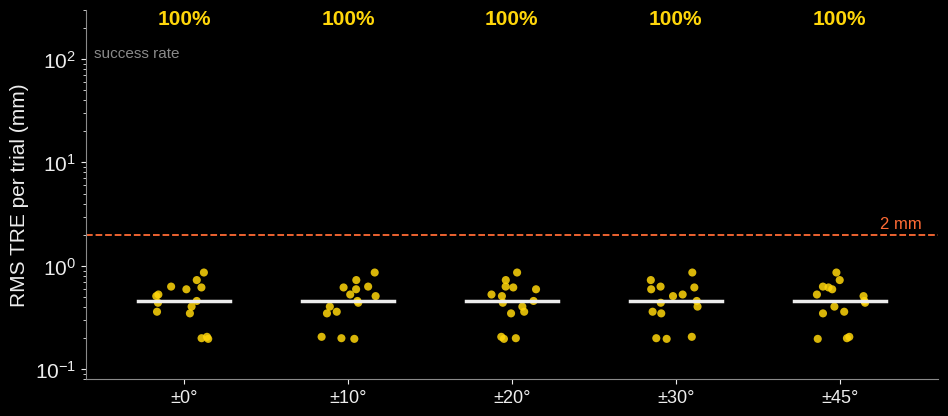

In [22]:
strip_plot("E4 init", ["±0°", "±10°", "±20°", "±30°", "±45°"], [Y] * 5, "13_rotation_guess.png")

# Response to PI feedback
> *Instead of looping over the 5 ground-truth fiducials, loop over the minimum number of fiducials. 3 views can solve, 2 views is iffy, but combinations of 2 views might give consistency.*

Below: why the repo cost fails with a missing ball (14), what happens when the cost loops over fewer fiducials (15), how few visible fiducials and views are enough (16), and whether view pairs can flag bad solves without ground truth (17).
The experiments live in `run_new.py` (cost and view experiments) and `run_det.py` (detector); this cell loads their CSVs or reruns them.

In [23]:
import importlib, robust, common, detector
for need, script in (("x3_pair_consistency.csv", "run_new.py"), ("d2_end_to_end.csv", "run_det.py")):
    if RUN_NEW_EXPERIMENTS or not os.path.exists(os.path.join(OUT, need)):
        %run {script} {OUT}
x1 = pd.read_csv(os.path.join(OUT, "x1_costs.csv")); x2 = pd.read_csv(os.path.join(OUT, "x2_min_fiducials.csv"))
x3 = pd.read_csv(os.path.join(OUT, "x3_pair_consistency.csv"))
d1 = pd.read_csv(os.path.join(OUT, "d1_detector.csv")); d2 = pd.read_csv(os.path.join(OUT, "d2_end_to_end.csv"))

## 14 · Why the repo cost fails: residual of every ball, at the truth vs at the solver's answer

**Assumptions:** Same trial as the 61 mm example; Residual = distance from each projected ball to its nearest detection; Repo cost at the true pose vs at the solver's answer.

view 1: at truth [134.4   0.4   0.3   0.5   0.3]  at answer [116.3  36.8  32.5   1.4  17.8]
view 2: at truth [ 0.6 60.7  1.3  0.3  0.8]  at answer [27.1 59.8 27.7 19.2 20.3]
view 3: at truth [4.000e-01 1.185e+02 1.000e-01 6.000e-01 1.000e+00]  at answer [13.4 77.4 33.5 20.6 20.1]


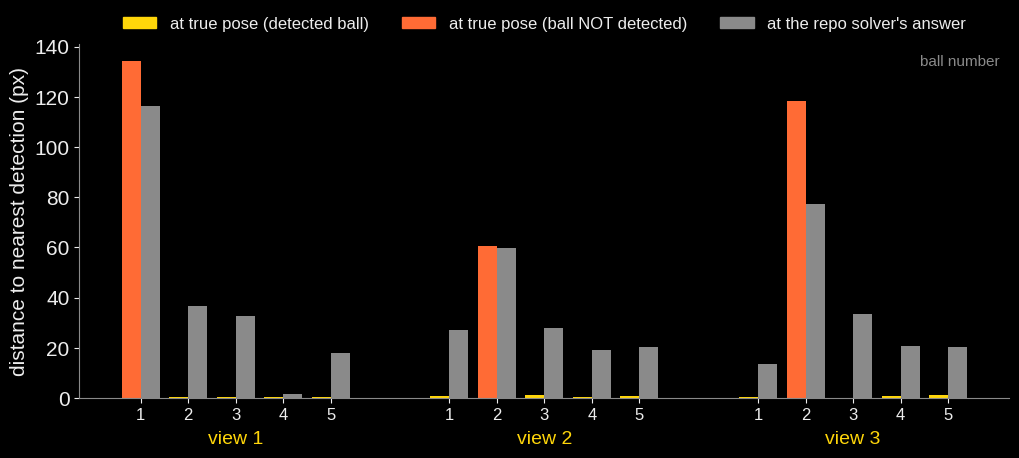

In [24]:
from robust import dist_matrix
fig, ax = plt.subplots(figsize=(12, 4.6)); xs = []; lab = []
for k in range(3):
    eT = dist_matrix(ex["p_gt"], P3[k], ex["Y"][k], XYZ).min(1); eS = dist_matrix(ex["p"], P3[k], ex["Y"][k], XYZ).min(1)
    for i in range(5):
        x = k * 6.5 + i
        ax.bar(x - .2, eT[i], .4, color=R if eT[i] > 10 else Y); ax.bar(x + .2, eS[i], .4, color=G)
        xs.append(x); lab.append(f"{i + 1}")
    ax.text(k * 6.5 + 2, -.13, f"view {k + 1}", ha="center", color=Y, fontsize=14, transform=ax.get_xaxis_transform())
    print(f"view {k + 1}: at truth {np.round(eT, 1)}  at answer {np.round(eS, 1)}")
ax.set_xticks(xs, lab, fontsize=12); ax.set_ylabel("distance to nearest detection (px)"); ax.set_ylim(0, None)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=Y, label="at true pose (detected ball)"), Patch(color=R, label="at true pose (ball NOT detected)"),
                   Patch(color=G, label="at the repo solver's answer")], frameon=False, fontsize=12, loc="upper center", ncol=3, bbox_to_anchor=(.5, 1.12))
ax.text(.99, .97, "ball number", color=G, fontsize=11, ha="right", va="top", transform=ax.transAxes)
save(fig, "14_residual_breakdown.png")

## 15 · Changing the cost: which fiducials the cost loops over

**Assumptions:** 3 views, 0.5 px, ±10° guess, normal Stage 1 start; Same CMA-ES settings for every cost; 15 trials per cell, same seeds across costs.

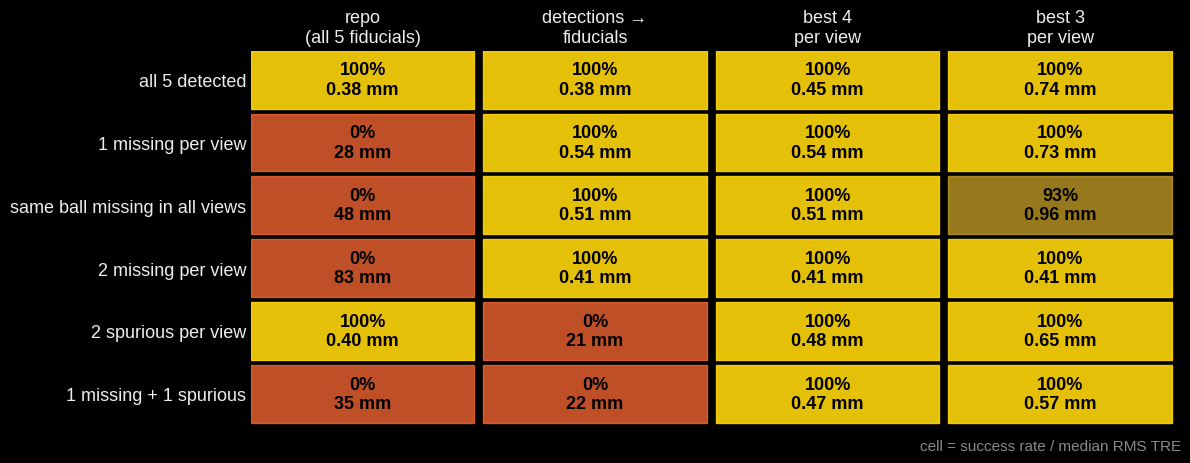

In [25]:
conds = list(dict.fromkeys(x1.condition)); costs = list(dict.fromkeys(x1.cost))
g = x1.groupby(["condition", "cost"]).rms_tre_vol
succ = g.apply(lambda v: (v < SUCCESS_MM).mean() * 100).unstack().loc[conds, costs]; med = g.median().unstack().loc[conds, costs]
fig, ax = plt.subplots(figsize=(12, 4.9))
for i, c in enumerate(conds):
    for j, f in enumerate(costs):
        sv, mv = succ.loc[c, f], med.loc[c, f]
        col = Y if sv == 100 else (R if sv < 50 else "#C9A227")
        ax.add_patch(plt.Rectangle((j, i), .96, .92, color=col, alpha=.9 if sv == 100 else .75))
        ax.text(j + .48, i + .46, f"{sv:.0f}%\n{mv:.2f} mm" if mv < 10 else f"{sv:.0f}%\n{mv:.0f} mm", ha="center", va="center",
                color=BG, fontsize=13, fontweight="bold")
ax.set_xlim(0, len(costs)); ax.set_ylim(len(conds), 0)
ax.set_xticks(np.arange(len(costs)) + .48, ["repo\n(all 5 fiducials)", "detections →\nfiducials", "best 4\nper view", "best 3\nper view"], fontsize=13)
ax.set_yticks(np.arange(len(conds)) + .46, conds, fontsize=13); ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
ax.xaxis.tick_top(); ax.text(len(costs), len(conds) + .35, "cell = success rate / median RMS TRE", color=G, fontsize=11, ha="right")
save(fig, "15_cost_comparison.png")

## 16 · Minimum number of visible fiducials × number of views

**Assumptions:** 'Detections → fiducials' cost; 0.5 px noise, ±10° guess; Missing balls chosen randomly per view; 15 trials per setting.

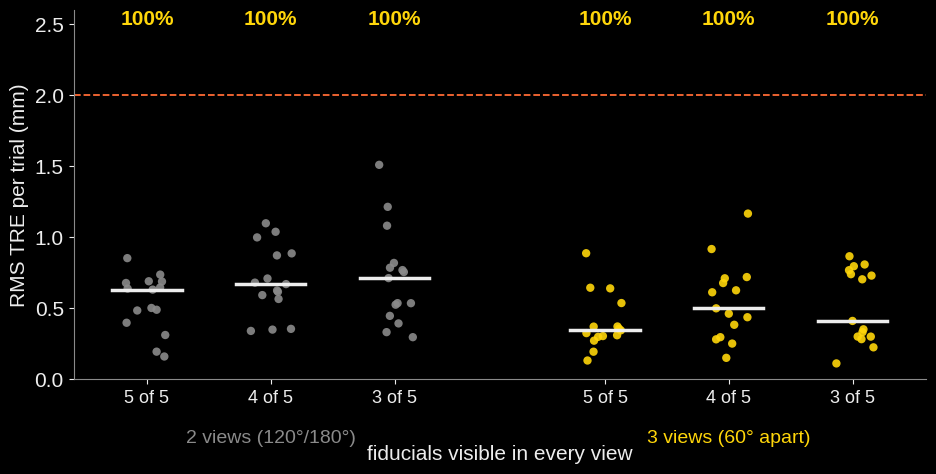

In [26]:
fig, ax = plt.subplots(figsize=(11, 4.8)); jit = np.random.default_rng(0); pos = 0; ticks = []; labs = []
for vn, col in (("2 views (120°/180°)", G), ("3 views (60° apart)", Y)):
    for vis in (5, 4, 3):
        v = x2[(x2.views == vn) & (x2.visible == vis)].rms_tre_vol.values
        ax.scatter(pos + jit.uniform(-.17, .17, len(v)), v, s=36, color=np.where(v < SUCCESS_MM, col, R), lw=0, alpha=.9)
        ax.plot([pos - .28, pos + .28], [np.median(v)] * 2, color=L, lw=2.5)
        ax.text(pos, .96, f"{(v < SUCCESS_MM).mean() * 100:.0f}%", ha="center", color=Y, fontweight="bold", transform=ax.get_xaxis_transform())
        ticks.append(pos); labs.append(f"{vis} of 5"); pos += 1
    ax.text(pos - 2, -.17, vn, ha="center", color=col, fontsize=14, transform=ax.get_xaxis_transform())
    pos += .7
ax.axhline(SUCCESS_MM, color=R, ls="--", lw=1.3); ax.set_ylim(0, 2.6)
ax.set_xticks(ticks, labs, fontsize=13); ax.set_ylabel("RMS TRE per trial (mm)"); ax.set_xlabel("fiducials visible in every view", labelpad=28)
save(fig, "16_min_fiducials_views.png")

## 17 · Do view pairs agree? A ground-truth-free consistency check

**Assumptions:** 'Detections → fiducials' cost; 3-view solve and 3 two-view re-solves from the same start; Spread s = largest RMS distance between pair solutions over the grid (no ground truth needed); 15 trials per condition.

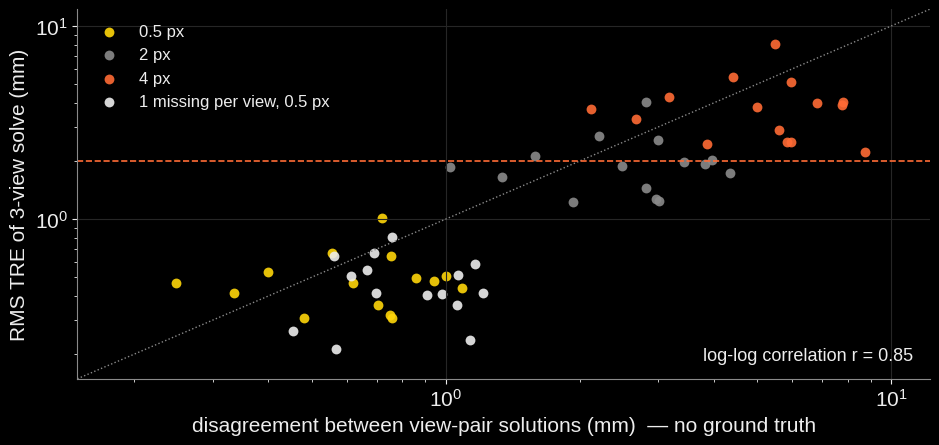

,tre_3view,pair_spread,tre_pair_best,tre_pair_worst
condition,,,,
0.5 px,0.47,0.72,0.39,0.77
2 px,1.88,2.82,1.55,3.07
4 px,3.79,5.60,2.96,6.09
"1 missing per view, 0.5 px",0.41,0.76,0.33,0.76


In [27]:
cmap = {"0.5 px": Y, "2 px": G, "4 px": R, "1 missing per view, 0.5 px": L}
fig, ax = plt.subplots(figsize=(11, 4.8))
for c, col in cmap.items():
    m = x3.condition == c
    ax.scatter(x3.pair_spread[m], x3.tre_3view[m], s=50, color=col, alpha=.9, lw=0, label=c)
lim = [min(x3.pair_spread.min(), x3.tre_3view.min()) * .7, max(x3.pair_spread.max(), x3.tre_3view.max()) * 1.4]
ax.plot(lim, lim, color=G, lw=1, ls=":"); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.axhline(SUCCESS_MM, color=R, ls="--", lw=1.2)
r_ = np.corrcoef(np.log(x3.pair_spread), np.log(x3.tre_3view))[0, 1]
ax.text(.98, .05, f"log-log correlation r = {r_:.2f}", ha="right", transform=ax.transAxes, fontsize=13)
ax.set_xlabel("disagreement between view-pair solutions (mm)  — no ground truth"); ax.set_ylabel("RMS TRE of 3-view solve (mm)")
ax.legend(frameon=False, fontsize=12, loc="upper left"); ax.grid(color="#262626")
save(fig, "17_pair_consistency.png")
x3.groupby("condition", sort=False)[["tre_3view", "pair_spread", "tre_pair_best", "tre_pair_worst"]].median().round(2)

# Fiducial detection (first pass)
The main sweeps skip image formation. Here a simple renderer makes synthetic X-ray views (body, hollow bone tubes crossing the cluster, glass balls, Poisson noise) and a classical detector finds the balls.

## 18 · Synthetic X-ray views and what the detector finds

**Assumptions:** Synthetic X-ray: water body 200 mm, 2 hollow bone tubes crossing the cluster, glass μ = 0.044/mm; Poisson photon noise, 1 px detector blur; Ball radius in px known from geometry; Not validated against real images.

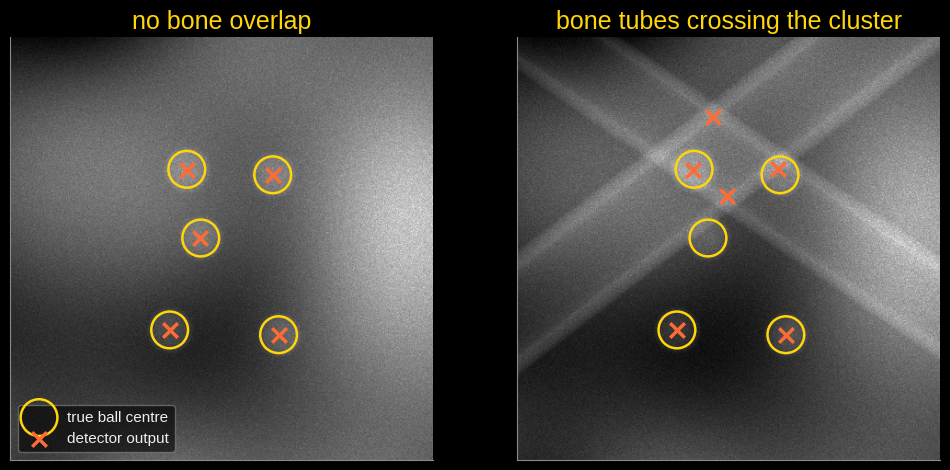

In [28]:
from detector import render, detect, ball_radii_px
rng = np.random.default_rng(500); Tq, _, _ = make_random_displacement_pose(1.0, rng, max_rot_deg=20, max_trans_mm=15)
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for a2, nb_, t in zip(axs, (0, 2), ("no bone overlap", "bone tubes crossing the cluster")):
    uv = robust.project_all(Tq, P3[0], XYZ); r_ = ball_radii_px(Tq, P3[0], XYZ)
    img = render(uv, r_, np.random.default_rng(1), I0=1e4, n_bones=nb_); d_, _ = detect(img, r_.mean())
    c = uv.mean(0).astype(int); w = 230
    a2.imshow(img[c[1] - w:c[1] + w, c[0] - w:c[0] + w], cmap="gray", extent=(c[0] - w, c[0] + w, c[1] + w, c[1] - w))
    a2.scatter(*uv.T, s=700, facecolors="none", edgecolors=Y, lw=1.8, label="true ball centre")
    a2.scatter(*d_.T, marker="x", color=R, s=110, lw=2.5, label="detector output")
    a2.set_xlim(c[0] - w, c[0] + w); a2.set_ylim(c[1] + w, c[1] - w)
    a2.set_title(t, color=Y); a2.set_xticks([]); a2.set_yticks([])
axs[0].legend(loc="lower left", fontsize=11, framealpha=.6, facecolor=BG, edgecolor=G)
save(fig, "18_detector_example.png")

## 19 · Detector recall and centre error vs dose

**Assumptions:** Same renderer as previous slide; 4 poses × 3 views = 12 images per point; Match = within 10 px (one-to-one); Up to 8 detections kept per view.

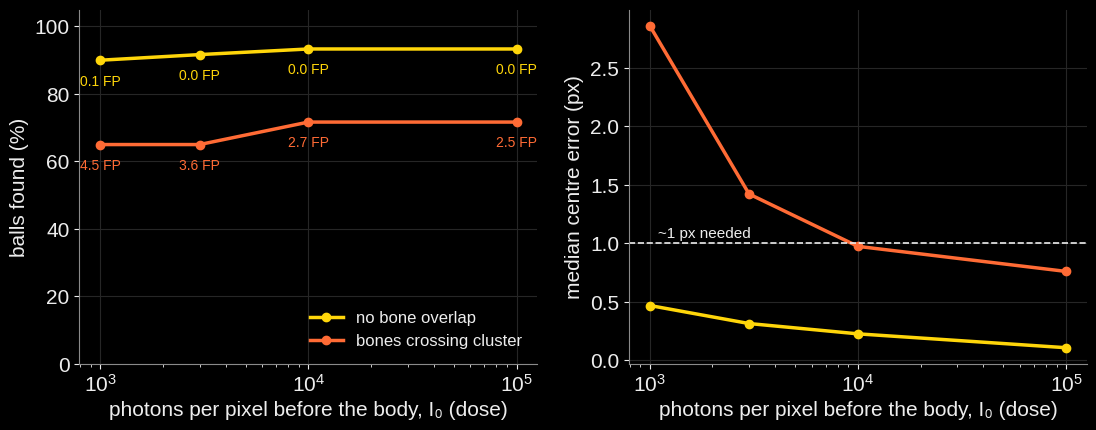

In [29]:
d1["errs_list"] = d1.errs.fillna("").apply(lambda s_: [float(x) for x in str(s_).split(";") if x not in ("", "nan")])
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for nb_, col, lab_ in ((0, Y, "no bone overlap"), (2, R, "bones crossing cluster")):
    sub = d1[d1.bones == nb_]; I0s = sorted(sub.I0.unique())
    rec = [sub[sub.I0 == i].recall.mean() * 100 for i in I0s]; fp = [sub[sub.I0 == i].fp.mean() for i in I0s]
    err = [np.median(sum(sub[sub.I0 == i].errs_list, [])) for i in I0s]
    axs[0].plot(I0s, rec, color=col, lw=2.5, marker="o", label=lab_)
    for i, f_ in zip(I0s, fp): axs[0].annotate(f"{f_:.1f} FP", (i, rec[I0s.index(i)]), xytext=(0, -18), textcoords="offset points", ha="center", color=col, fontsize=10)
    axs[1].plot(I0s, err, color=col, lw=2.5, marker="o", label=lab_)
axs[0].set_ylim(0, 105); axs[0].set_ylabel("balls found (%)"); axs[1].set_ylabel("median centre error (px)")
axs[1].axhline(1, color=L, ls="--", lw=1.2); axs[1].text(1.1e3, 1.05, "~1 px needed", color=L, fontsize=11)
for a2 in axs: a2.set_xscale("log"); a2.set_xlabel("photons per pixel before the body, I₀ (dose)"); a2.grid(color="#262626")
axs[0].legend(frameon=False, fontsize=12, loc="lower right")
save(fig, "19_detector_dose.png")

## 20 · End to end: image → detector → solver → TRE

**Assumptions:** Images → detector → solver, I0 = 10⁴; 3 views, ±10° guess; 8 poses per background; Rotation guess still from ground truth.

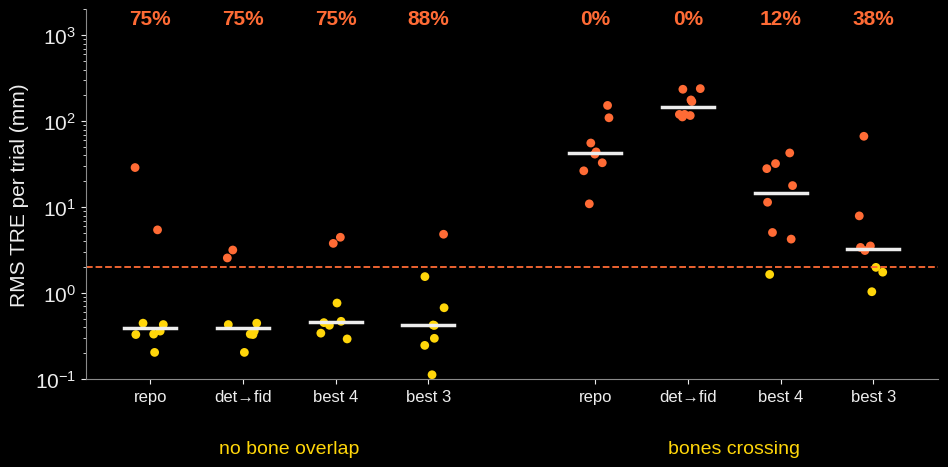

success  median
bones cost                                   
0     repo (all 5 fiducials)     75.0    0.40
      detections → fiducials     75.0    0.40
      best 4 per view            75.0    0.46
      best 3 per view            87.5    0.42
2     repo (all 5 fiducials)      0.0   42.76
      detections → fiducials      0.0  145.09
      best 4 per view            12.5   14.64
      best 3 per view            37.5    3.27

In [30]:
order = list(dict.fromkeys(d2.cost)); fig, ax = plt.subplots(figsize=(11, 4.8)); jit = np.random.default_rng(0); pos = 0; ticks = []
for nb_, t in ((0, "no bone overlap"), (2, "bones crossing")):
    for f_ in order:
        v = d2[(d2.bones == nb_) & (d2.cost == f_)].rms_tre_vol.values
        ax.scatter(pos + jit.uniform(-.17, .17, len(v)), np.clip(v, .05, None), s=40, color=np.where(v < SUCCESS_MM, Y, R), lw=0)
        ax.plot([pos - .28, pos + .28], [np.median(v)] * 2, color=L, lw=2.5)
        ax.text(pos, .96, f"{(v < SUCCESS_MM).mean() * 100:.0f}%", ha="center", color=Y if (v < SUCCESS_MM).all() else R,
                fontweight="bold", transform=ax.get_xaxis_transform())
        ticks.append(pos); pos += 1
    ax.text(pos - 2.5, -.2, t, ha="center", color=Y, fontsize=14, transform=ax.get_xaxis_transform()); pos += .8
ax.set_yscale("log"); ax.axhline(SUCCESS_MM, color=R, ls="--", lw=1.3); ax.set_ylim(.1, 2e3)
ax.set_xticks(ticks, ["repo", "det→fid", "best 4", "best 3"] * 2, fontsize=12); ax.set_ylabel("RMS TRE per trial (mm)")
save(fig, "20_end_to_end.png")
d2.groupby(["bones", "cost"], sort=False).rms_tre_vol.agg(success=lambda v: (v < SUCCESS_MM).mean() * 100, median="median").round(2)

## 21 · NEW · How often do two balls overlap in the X-ray?
Found while debugging the detector: misses on clean images were two balls overlapping in projection. Here: for 500 random poses, the closest pair of projected balls at every view angle around the orbit.

**Assumptions:** 500 random poses (20° + 15 mm); 10 mm balls, assumed C-arm geometry; Overlap = closest projected pair nearer than 1 ball diameter; Views on one orbit plane.

{np.int64(0): np.float64(58.0), np.int64(10): np.float64(43.0), np.int64(20): np.float64(28.0), np.int64(30): np.float64(11.0), np.int64(40): np.float64(17.0), np.int64(50): np.float64(29.0), np.int64(60): np.float64(36.0), np.int64(70): np.float64(39.0), np.int64(80): np.float64(34.0), np.int64(90): np.float64(23.0), np.int64(100): np.float64(8.0), np.int64(110): np.float64(0.0), np.int64(120): np.float64(6.0), np.int64(130): np.float64(10.0), np.int64(140): np.float64(14.0), np.int64(150): np.float64(27.0), np.int64(160): np.float64(40.0), np.int64(170): np.float64(55.0), np.int64(180): np.float64(53.0), np.int64(190): np.float64(42.0), np.int64(200): np.float64(26.0), np.int64(210): np.float64(9.0), np.int64(220): np.float64(11.0), np.int64(230): np.float64(23.0), np.int64(240): np.float64(32.0), np.int64(250): np.float64(36.0), np.int64(260): np.float64(31.0), np.int64(270): np.float64(22.0), np.int64(280): np.float64(9.0), np.int64(290): np.float64(0.0), np.int64(300): np.float64(

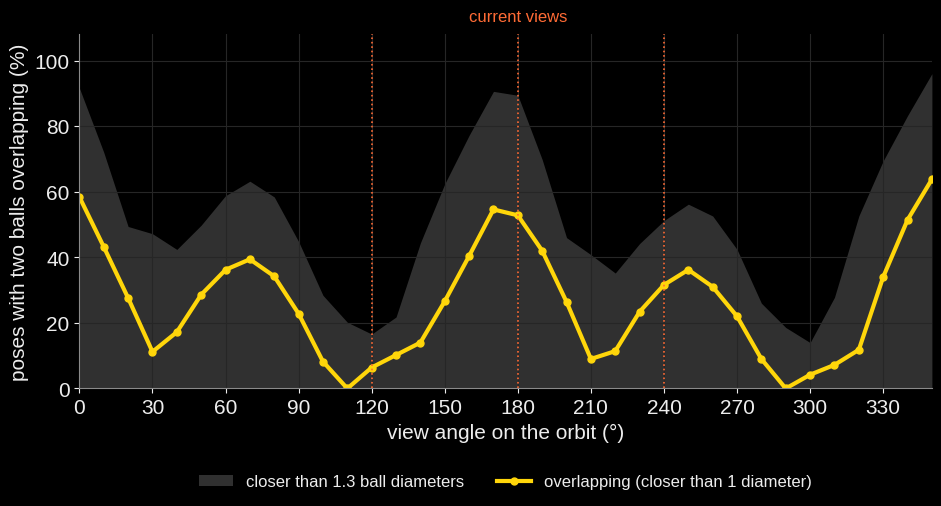

In [31]:
from detector import ball_radii_px
angles = np.arange(0, 360, 10); rng = np.random.default_rng(0)
poses = [make_random_displacement_pose(1.0, rng, max_rot_deg=20, max_trans_mm=15)[0] for _ in range(500)]
ov, close = [], []
for a in angles:
    P = views((a,))[0]; g_ = []
    for Tq in poses:
        uv = robust.project_all(Tq, P, XYZ); Dm = np.linalg.norm(uv[:, None] - uv[None], axis=2); np.fill_diagonal(Dm, np.inf)
        g_.append(Dm.min() / (2 * ball_radii_px(Tq, P, XYZ).mean()))
    g_ = np.array(g_); ov.append((g_ < 1).mean() * 100); close.append((g_ < 1.3).mean() * 100)
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.fill_between(angles, close, color=G, alpha=.35, lw=0, label="closer than 1.3 ball diameters")
ax.plot(angles, ov, color=Y, lw=3, marker="o", ms=5, label="overlapping (closer than 1 diameter)")
for a in REAL3: ax.axvline(a, color=R, lw=1.2, ls=":")
ax.text(180, 112, "current views", color=R, ha="center", fontsize=12)
ax.set_xlim(0, 350); ax.set_ylim(0, 108); ax.set_xticks(range(0, 360, 30))
ax.set_xlabel("view angle on the orbit (°)"); ax.set_ylabel("poses with two balls overlapping (%)")
ax.legend(frameon=False, fontsize=12, loc="upper center", bbox_to_anchor=(.5, -.2), ncol=2); ax.grid(color="#262626")
print(dict(zip(angles, np.round(ov, 0))))
save(fig, "21_ball_overlap.png")